# v11 B (GPU 0): LESION, then train the next phase (count-matched)
The paper's lesion: the chosen neurons are re-drawn as at initialisation, then the model trains its next language (1,000 steps, normal masked loss, learning rate 2e-4).
- Conditions: untouched · self@1.0 vs task@1.0 (n_max per layer) · self@0.5 vs task@0.5 vs look-alike@0.5.
- Starts: distant phases 10, 11, 12, 40, 41, 42 · related 10-15. 3 seeds. Seed 0 of everything first. 12 x 3 x 6 = 216 runs. Finished runs are skipped on a re-run.
Results: `analysis/v11/train_next/` · progress: `tail -f logs/v11_B_lesion_next.log`

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"; LOG = "v11_B_lesion_next"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
FILES, HF_REPO = [], None
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)
if not FILES:
    print("could not list the HF repo: only checkpoints already on this machine will be used")

def have(run, ph):
    return bool(glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"))

def get(run, phases):
    """download what is missing; returns the phases that are on this machine afterwards"""
    ok = []
    for ph in phases:
        if not have(run, ph):
            name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
            if name:
                try:
                    hf_hub_download(HF_REPO, name[0], local_dir="runs")
                except Exception as e:
                    print("download failed:", run, ph, type(e).__name__, e)
        if have(run, ph):
            ok.append(ph)
        else:
            print("not available (not here, not on HF):", run, ph)
    return ok

def run(langset, *cmd):
    """one call of core_v11.py; output shown here AND appended to logs/<LOG>.log (watch with: tail -f logs/<LOG>.log)"""
    env = {**os.environ, "CML_LANGSET": langset}; os.makedirs("logs", exist_ok=True)
    p = subprocess.Popen([sys.executable, "-u", "core_v11.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    with open(f"logs/{LOG}.log", "a") as log:
        for line in p.stdout:
            print(line, end=""); log.write(line); log.flush()
    p.wait(); print("exit code", p.returncode)

def summary(part, out=None):
    cmd = [sys.executable, "core_v11.py", "--summarize", "--part", part] + (["--out", out] if out else [])
    r = subprocess.run(cmd, capture_output=True, text=True); print(r.stdout[-12000:]); print(r.stderr[-3000:])

DIST, HIN, MIX, REL = "v4b_continual_s0", "v4b_only_hi_s0", "v6b_mixed_s0", "v8_indic_continual_s0"

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


In [2]:
STARTS = [("distant", "distant", DIST, p) for p in [10, 11, 12, 40, 41, 42]] + [("indic", "related", REL, p) for p in [10, 11, 12, 13, 14, 15]]

for seeds in ["0", "1,2"]:
    for langset, fam, r, ph in STARTS:
        if get(r, [ph]):
            run(langset, "--part", "train", "--task", "next", "--mode", "lesion", "--family", fam, "--model", f"{fam}{ph}={r}:{ph}", "--seeds", seeds)
    summary("train", "train_next")

start model: distant10 = v4b_continual_s0 phase 10 (last trained on hi) | languages hi, zh, ar


  enc0: working 2560, self 1313, task 1247 -> count-matched n_max 1247
  enc1: working 2560, self 1133, task 1427 -> count-matched n_max 1133
  enc2: working 2560, self 1273, task 1287 -> count-matched n_max 1273
  enc3: working 2560, self 1552, task 1008 -> count-matched n_max 1008
  dec0: working 2560, self 1331, task 1229 -> count-matched n_max 1229
  dec1: working 2560, self 1039, task 1521 -> count-matched n_max 1039
  dec2: working 2560, self 1108, task 1452 -> count-matched n_max 1108
  dec3: working 2560, self 1663, task 897 -> count-matched n_max 897
  self found in 6s


  next language = zh (phase 11 of the normal schedule)
runs to do in this call: 6 (mode lesion; conditions ['none', 'self@1.0', 'task@1.0', 'self@0.5', 'task@0.5', 'look@0.5']; seeds [0]; finished runs are skipped)


  distant10 | next | none    | none      | seed 0 | 0 neurons | loss 6.419 -> 2.367 | chrF 2.5 -> 22.0 | 93s | left in this call: 5 runs, about 8 min


  distant10 | next | lesion  | self@1.0  | seed 0 | 8934 neurons | loss 7.997 -> 2.479 | chrF 0.4 -> 20.5 | 92s | left in this call: 4 runs, about 6 min


  distant10 | next | lesion  | task@1.0  | seed 0 | 8934 neurons | loss 8.002 -> 2.438 | chrF 1.5 -> 21.3 | 97s | left in this call: 3 runs, about 5 min


... (304 outputs left out)

  related15 | next | lesion  | task@0.5  | seed 2 | 4406 neurons | loss 3.330 -> 1.692 | chrF 39.6 -> 47.1 | 96s | left in this call: 1 runs, about 2 min


  related15 | next | lesion  | look@0.5  | seed 2 | 4406 neurons | loss 3.385 -> 1.694 | chrF 36.9 -> 47.5 | 96s | left in this call: 0 runs, about 0 min
done


exit code 0


=== train (train_next): held-out loss on the trained language MINUS the untouched model's, same start and seed ===
average over starts and seeds; step 0 = right after the intervention, before any training
step                         0       100     300     1000
family  mode   dose group                                
distant lesion 0.5  look   0.2432  0.1057  0.0756  0.0520
                    self   0.4579  0.1517  0.0946  0.0587
                    task   0.1872  0.0940  0.0682  0.0487
               1.0  self   1.5519  0.4482  0.2481  0.1498
                    task   0.8626  0.2489  0.1678  0.1166
related lesion 0.5  look   0.2476  0.1009  0.0689  0.0485
                    self   0.5810  0.1354  0.0842  0.0566
                    task   0.1931  0.0874  0.0621  0.0447
               1.0  self   2.1966  0.3731  0.2258  0.1440
                    task   0.8109  0.2236  0.1484  0.1048

--- self vs task: in how many runs is the self version worse (one run = one start x one seed)
 fam

=== train (train_next): held-out loss on the trained language MINUS the untouched model's, same start and seed ===
average over starts and seeds; step 0 = right after the intervention, before any training
step                         0       100     300     1000
family  mode   dose group                                
distant lesion 0.5  look   0.2432  0.1057  0.0756  0.0520
                    self   0.4579  0.1517  0.0946  0.0587
                    task   0.1872  0.0940  0.0682  0.0487
               1.0  self   1.5519  0.4482  0.2481  0.1498
                    task   0.8626  0.2489  0.1678  0.1166
related lesion 0.5  look   0.2476  0.1009  0.0689  0.0485
                    self   0.5810  0.1354  0.0842  0.0566
                    task   0.1931  0.0874  0.0621  0.0447
               1.0  self   2.1966  0.3731  0.2258  0.1440
                    task   0.8109  0.2236  0.1484  0.1048

--- self vs task: in how many runs is the self version worse (one run = one start x one seed)
 fam

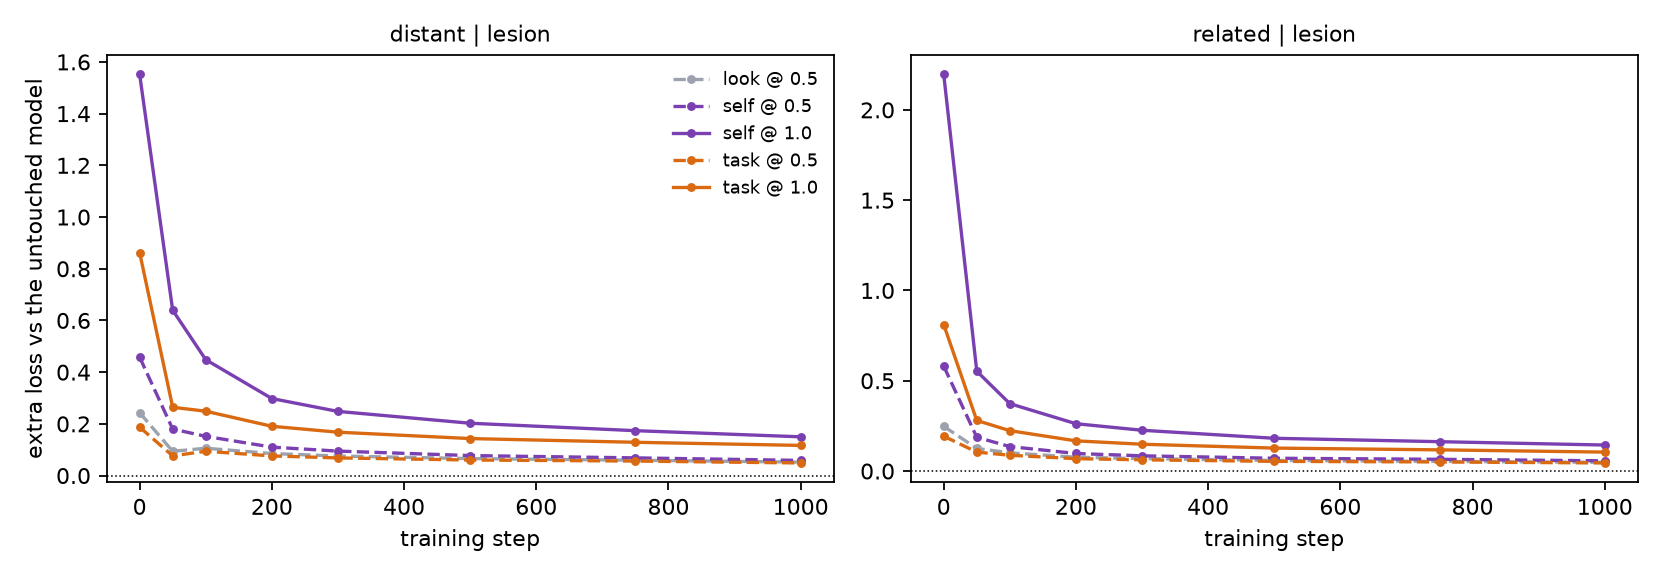

In [3]:
summary("train", "train_next")
if os.path.exists("analysis/v11/train_next/curves.png"): display(Image("analysis/v11/train_next/curves.png"))